In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [53]:
df = pd.read_csv('Customer_Experience_Intelligence_data.csv')
df

,customer_id,age,location,total_orders,avg_order_value,days_since_last_order,support_tickets,customer_satisfaction,review_text,sentiment,churn
0,CUST00001,25,Kochi,7,351.07,11,0,2.09,The overall experience was disappointing and n...,Negative,0
1,CUST00002,52,Kochi,6,4266.62,16,2,2.73,I am unhappy with the service and would not or...,Negative,0
2,CUST00003,55,Kozhikode,8,3920.22,11,0,2.51,The app caused problems and I could not comple...,Negative,1
3,CUST00004,22,Kollam,6,2519.91,1,1,3.00,The support team did not handle my complaint p...,Negative,0
4,CUST00005,23,Thiruvananthapuram,24,3736.10,32,0,4.10,I had a pleasant experience and would recommen...,Positive,0
...,...,...,...,...,...,...,...,...,...,...,...
4995,CUST04996,25,Chennai,8,1047.96,9,4,4.38,I am really satisfied with the quality and del...,Positive,0
4996,CUST04997,31,Kollam,9,893.06,6,1,3.28,"The product was fine, but delivery could have ...",Neutral,0
4997,CUST04998,48,Kochi,9,983.06,10,3,3.57,Overall the order was okay and could be improved.,Neutral,1
4998,CUST04999,26,Kollam,5,640.12,18,0,3.88,The experience was average with nothing unusual.,Neutral,0


In [54]:
df.head()

,customer_id,age,location,total_orders,avg_order_value,days_since_last_order,support_tickets,customer_satisfaction,review_text,sentiment,churn
0,CUST00001,25,Kochi,7,351.07,11,0,2.09,The overall experience was disappointing and n...,Negative,0
1,CUST00002,52,Kochi,6,4266.62,16,2,2.73,I am unhappy with the service and would not or...,Negative,0
2,CUST00003,55,Kozhikode,8,3920.22,11,0,2.51,The app caused problems and I could not comple...,Negative,1
3,CUST00004,22,Kollam,6,2519.91,1,1,3.00,The support team did not handle my complaint p...,Negative,0
4,CUST00005,23,Thiruvananthapuram,24,3736.10,32,0,4.10,I had a pleasant experience and would recommen...,Positive,0


In [55]:
df.columns

Index(['customer_id', 'age', 'location', 'total_orders', 'avg_order_value',
       'days_since_last_order', 'support_tickets', 'customer_satisfaction',
       'review_text', 'sentiment', 'churn'],
      dtype='object')

In [56]:
df.shape

(5000, 11)

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   customer_id            5000 non-null   object 
 1   age                    5000 non-null   int64  
 2   location               5000 non-null   object 
 3   total_orders           5000 non-null   int64  
 4   avg_order_value        5000 non-null   float64
 5   days_since_last_order  5000 non-null   int64  
 6   support_tickets        5000 non-null   int64  
 7   customer_satisfaction  5000 non-null   float64
 8   review_text            5000 non-null   object 
 9   sentiment              5000 non-null   object 
 10  churn                  5000 non-null   int64  
dtypes: float64(2), int64(5), object(4)
memory usage: 429.8+ KB


In [58]:
df.dtypes

customer_id               object
age                        int64
location                  object
total_orders               int64
avg_order_value          float64
days_since_last_order      int64
support_tickets            int64
customer_satisfaction    float64
review_text               object
sentiment                 object
churn                      int64
dtype: object

### Check null values

In [59]:
df.isnull().sum()

customer_id              0
age                      0
location                 0
total_orders             0
avg_order_value          0
days_since_last_order    0
support_tickets          0
customer_satisfaction    0
review_text              0
sentiment                0
churn                    0
dtype: int64

### Check duplicate values

In [60]:
df.duplicated().sum()

np.int64(0)

# EDA

In [61]:
df.describe()

,age,total_orders,avg_order_value,days_since_last_order,support_tickets,customer_satisfaction,churn
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,39.026200,9.304200,2371.321712,17.454200,1.201000,3.365338,0.249400
std,12.508493,6.564867,1216.793047,10.297432,1.102562,0.893929,0.432709
min,18.000000,1.000000,300.000000,1.000000,0.000000,1.080000,0.000000
25%,28.000000,5.000000,1318.477500,10.000000,0.000000,2.630000,0.000000
50%,39.000000,8.000000,2371.930000,17.000000,1.000000,3.380000,0.000000
75%,50.000000,12.000000,3433.165000,25.000000,2.000000,4.090000,0.000000
max,60.000000,70.000000,4496.780000,58.000000,7.000000,5.000000,1.000000


### Check numerical values

In [62]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
numeric_cols

['age',
 'total_orders',
 'avg_order_value',
 'days_since_last_order',
 'support_tickets',
 'customer_satisfaction',
 'churn']

### Check categorical values

In [63]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()
categorical_cols

['customer_id', 'location', 'review_text', 'sentiment']

In [64]:
df["location"].value_counts()

location
Kochi                 525
Hyderabad             515
Kozhikode             514
Bengaluru             514
Thiruvananthapuram    511
Thrissur              501
Kollam                496
Pune                  494
Chennai               467
Mumbai                463
Name: count, dtype: int64

### Sentiment Target

In [65]:
df["sentiment"].value_counts()

sentiment
Negative    1718
Positive    1672
Neutral     1610
Name: count, dtype: int64

### Churn Target

In [66]:
df["churn"].value_counts()

churn
0    3753
1    1247
Name: count, dtype: int64

### Sentiment Distribution

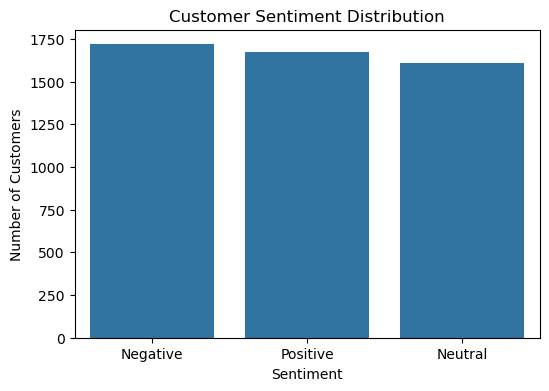

In [67]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="sentiment")

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Customers")

plt.show()

### Sentiment Analysis

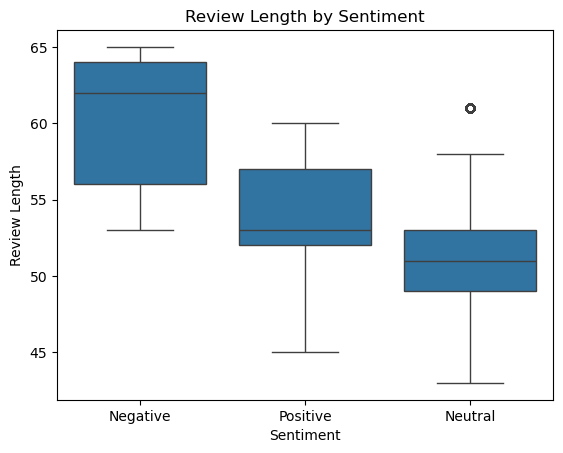

In [68]:
df["review_length"] = df["review_text"].str.len()

sns.boxplot(data=df, x="sentiment", y="review_length")

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Review Length")

plt.show()

In [69]:
df.drop(columns=["review_length"], inplace=True)

### Churn Distribution

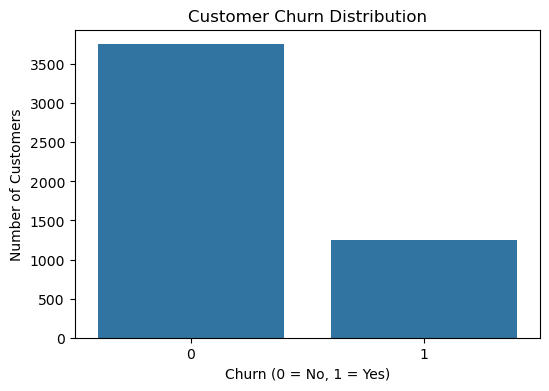

In [70]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

## Feature vs Churn Analysis

### Age vs Churn

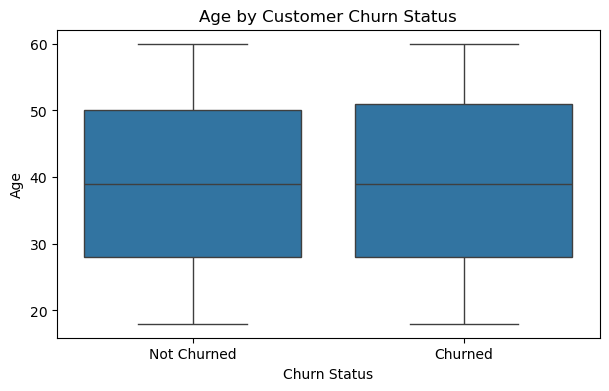

In [71]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="age")

plt.title("Age by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Age")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Total Orders vs Churn

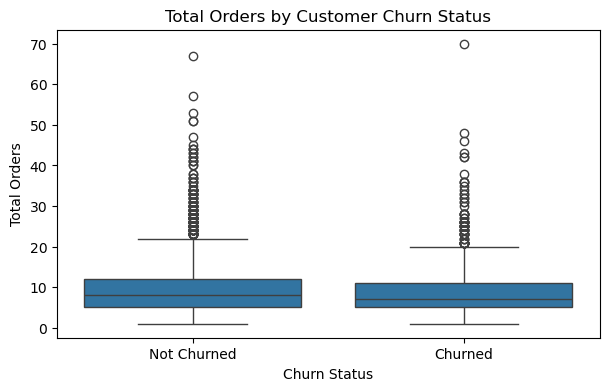

In [72]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="total_orders")

plt.title("Total Orders by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Orders")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Average Order Value vs Churn

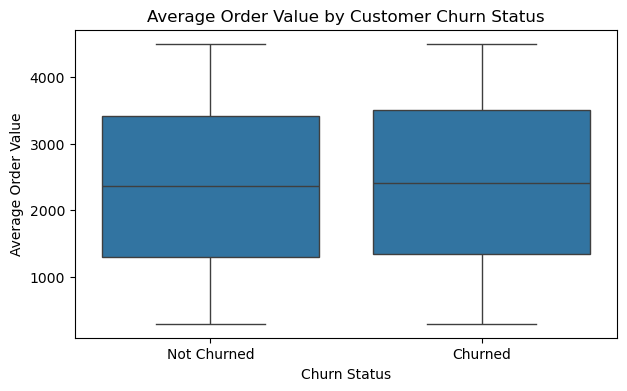

In [73]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="avg_order_value")

plt.title("Average Order Value by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Average Order Value")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Days Since Last Order vs Churn

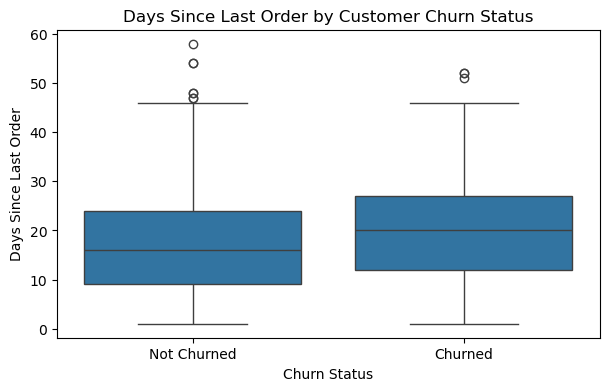

In [74]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="days_since_last_order")

plt.title("Days Since Last Order by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Days Since Last Order")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Support Tickets vs Churn

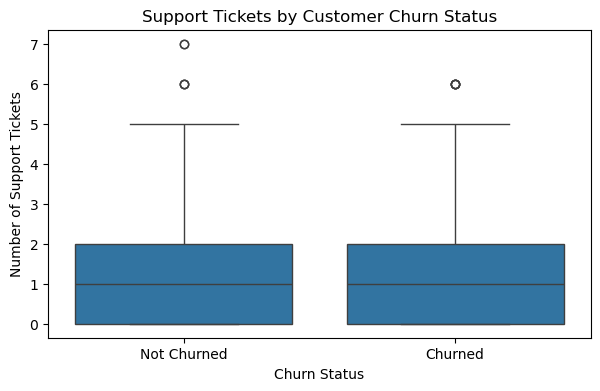

In [75]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="support_tickets")

plt.title("Support Tickets by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Number of Support Tickets")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Customer Satisfaction vs Churn

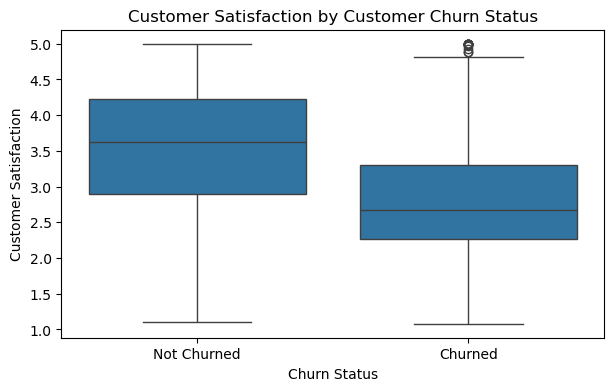

In [76]:
plt.figure(figsize=(7, 4))

sns.boxplot(data=df, x="churn", y="customer_satisfaction")

plt.title("Customer Satisfaction by Customer Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Customer Satisfaction")

plt.xticks([0, 1], ["Not Churned", "Churned"])

plt.show()

### Correlation Analysis

In [77]:
correlation_matrix = df[['age', 'total_orders', 'avg_order_value', 'days_since_last_order','support_tickets', 'customer_satisfaction', 'churn']].corr()

correlation_matrix

,age,total_orders,avg_order_value,days_since_last_order,support_tickets,customer_satisfaction,churn
age,1.000000,0.008061,-0.004849,0.003077,-0.012348,-0.001878,0.007071
total_orders,0.008061,1.000000,0.019389,-0.022666,0.000782,-0.011920,-0.029952
avg_order_value,-0.004849,0.019389,1.000000,0.015488,0.005260,-0.015296,0.015424
days_since_last_order,0.003077,-0.022666,0.015488,1.000000,-0.012465,-0.000384,0.121916
support_tickets,-0.012348,0.000782,0.005260,-0.012465,1.000000,0.000395,0.075202
customer_satisfaction,-0.001878,-0.011920,-0.015296,-0.000384,0.000395,1.000000,-0.346386
churn,0.007071,-0.029952,0.015424,0.121916,0.075202,-0.346386,1.000000


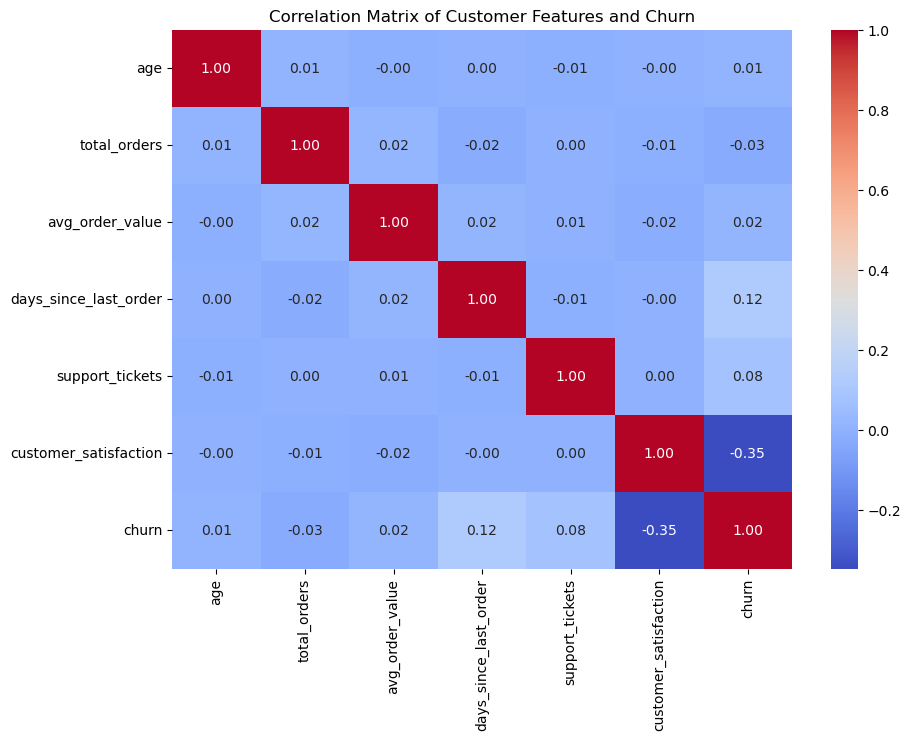

In [78]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Customer Features and Churn")
plt.show()

### Total Orders outlier Outlier Detection

In [79]:
Q1 = df["total_orders"].quantile(0.25)
Q3 = df["total_orders"].quantile(0.75)

IQR = Q3 - Q1

outliers = df[
    (df["total_orders"] < Q1 - 1.5 * IQR) |
    (df["total_orders"] > Q3 + 1.5 * IQR)
]

print("Number of outliers:", len(outliers))

Number of outliers: 224


### Days Since Last Order Outlier Detection

In [80]:
Q1 = df["days_since_last_order"].quantile(0.25)
Q3 = df["days_since_last_order"].quantile(0.75)

IQR = Q3 - Q1

outliers = df[
    (df["days_since_last_order"] < Q1 - 1.5 * IQR) |
    (df["days_since_last_order"] > Q3 + 1.5 * IQR)
]

print("Number of outliers:", len(outliers))

Number of outliers: 8


### Support Tickets Outlier Detection

In [81]:
Q1 = df["support_tickets"].quantile(0.25)
Q3 = df["support_tickets"].quantile(0.75)

IQR = Q3 - Q1

outliers = df[
    (df["support_tickets"] < Q1 - 1.5 * IQR) |
    (df["support_tickets"] > Q3 + 1.5 * IQR)
]

print("Number of outliers:", len(outliers))

Number of outliers: 10


### Customer Satisfaction Outlier Detection

In [82]:
Q1 = df["customer_satisfaction"].quantile(0.25)
Q3 = df["customer_satisfaction"].quantile(0.75)

IQR = Q3 - Q1

outliers = df[
    (df["customer_satisfaction"] < Q1 - 1.5 * IQR) |
    (df["customer_satisfaction"] > Q3 + 1.5 * IQR)
]

print("Number of outliers:", len(outliers))

Number of outliers: 0


In [83]:
## No outlier removal will be performed unless a value is identified as an actual data error